In [1]:
import pandas as pd
import numpy as np

# Load dataset
df = pd.read_csv("cleaned_sales.csv")

# Dataset overview
print("Dataset Loaded Successfully!")
print("Rows and Columns:", df.shape)

# First 5 records
display(df.head())

Dataset Loaded Successfully!
Rows and Columns: (1000, 17)


,Order_ID,Order_Date,Customer_ID,Customer_Name,Age,Gender,City,Product,Category,Quantity,Unit_Price,Total_Sales,Order_Year,Order_Month,Order_Day,Age_Group,Sales_Outlier
0,ORD100002,25-02-2025,CUST5529,Customer_227,30,Female,Bengaluru,Rice,Grocery,7,2829.77,19808.39,2025,2,25,Adult,False
1,ORD100003,14-10-2025,CUST3127,Customer_182,63,Male,Bengaluru,Book,Education,5,27906.16,139530.80,2025,10,14,Senior,False
2,ORD100004,13-05-2025,CUST8887,Customer_487,62,Female,Bengaluru,Book,Education,8,37491.06,299928.48,2025,5,13,Senior,False
3,ORD100005,02-12-2025,CUST2515,Customer_470,65,Female,Kolkata,Mobile,Electronics,9,28541.36,256872.24,2025,12,2,Senior,False
4,ORD100006,20-11-2025,CUST4796,Customer_380,44,Male,Bengaluru,Rice,Grocery,10,14036.59,140365.90,2025,11,20,Middle_Aged,False


In [2]:
# Column names and data types
df.info()

# Missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Duplicate rows
print("\nDuplicate Rows:", df.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 17 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Order_ID       1000 non-null   object 
 1   Order_Date     1000 non-null   object 
 2   Customer_ID    1000 non-null   object 
 3   Customer_Name  1000 non-null   object 
 4   Age            1000 non-null   int64  
 5   Gender         1000 non-null   object 
 6   City           1000 non-null   object 
 7   Product        1000 non-null   object 
 8   Category       1000 non-null   object 
 9   Quantity       1000 non-null   int64  
 10  Unit_Price     1000 non-null   float64
 11  Total_Sales    1000 non-null   float64
 12  Order_Year     1000 non-null   int64  
 13  Order_Month    1000 non-null   int64  
 14  Order_Day      1000 non-null   int64  
 15  Age_Group      1000 non-null   object 
 16  Sales_Outlier  1000 non-null   bool   
dtypes: bool(1), float64(2), int64(5), object(9)
memory us

In [3]:
# Missing values check
print("Total Missing Values:", df.isnull().sum().sum())

# Duplicate complete rows
print("Duplicate Rows:", df.duplicated().sum())

# Duplicate Order IDs
print("Duplicate Order IDs:", df["Order_ID"].duplicated().sum())

# Unique customers and orders
print("Unique Customers:", df["Customer_ID"].nunique())
print("Unique Orders:", df["Order_ID"].nunique())

Total Missing Values: 0
Duplicate Rows: 0
Duplicate Order IDs: 8
Unique Customers: 947
Unique Orders: 992


In [4]:
# Find duplicate Order IDs
duplicate_orders = df[
    df["Order_ID"].duplicated(keep=False)
].sort_values("Order_ID")

# Show duplicate order details
display(
    duplicate_orders[
        ["Order_ID", "Customer_ID", "Order_Date",
         "Product", "Category", "Quantity", "Total_Sales"]
    ]
)

# Count records for each duplicate Order ID
print("\nDuplicate Order ID Counts:")
print(duplicate_orders["Order_ID"].value_counts())

,Order_ID,Customer_ID,Order_Date,Product,Category,Quantity,Total_Sales
48,ORD100050,CUST5523,03-10-2025,Chair,Furniture,9,277513.83
118,ORD100050,CUST3194,22-01-2025,Book,Education,2,51591.10
238,ORD100050,CUST8467,01-03-2025,Book,Education,3,8582.49
358,ORD100050,CUST6467,11-02-2025,Rice,Grocery,7,318362.73
478,ORD100050,CUST8225,22-11-2025,Rice,Grocery,8,311660.72
598,ORD100050,CUST8859,21-02-2025,Laptop,Electronics,7,141013.88
718,ORD100050,CUST7824,06-11-2025,Rice,Grocery,4,170570.36
838,ORD100050,CUST5585,03-08-2025,Chair,Furniture,9,258727.23
958,ORD100050,CUST7188,09-02-2025,Mobile,Electronics,1,34619.77



Duplicate Order ID Counts:
Order_ID
ORD100050    9
Name: count, dtype: int64


In [5]:
# Inspect all 9 records of ORD100050
order_check = df[df["Order_ID"] == "ORD100050"]

display(order_check)

print("Total Records:", len(order_check))
print("Unique Customers:", order_check["Customer_ID"].nunique())
print("Unique Products:", order_check["Product"].nunique())
print("Total Sales:", order_check["Total_Sales"].sum())

,Order_ID,Order_Date,Customer_ID,Customer_Name,Age,Gender,City,Product,Category,Quantity,Unit_Price,Total_Sales,Order_Year,Order_Month,Order_Day,Age_Group,Sales_Outlier
48,ORD100050,03-10-2025,CUST5523,Customer_432,41,Male,Pune,Chair,Furniture,9,30834.87,277513.83,2025,10,3,Middle_Aged,False
118,ORD100050,22-01-2025,CUST3194,Customer_114,34,Male,Kolkata,Book,Education,2,25795.55,51591.10,2025,1,22,Adult,False
238,ORD100050,01-03-2025,CUST8467,Customer_104,23,Male,Bengaluru,Book,Education,3,2860.83,8582.49,2025,3,1,Young,False
358,ORD100050,11-02-2025,CUST6467,Customer_181,24,Female,Pune,Rice,Grocery,7,45480.39,318362.73,2025,2,11,Young,False
478,ORD100050,22-11-2025,CUST8225,Customer_468,64,Male,Bengaluru,Rice,Grocery,8,38957.59,311660.72,2025,11,22,Senior,False
598,ORD100050,21-02-2025,CUST8859,Customer_53,41,Male,Unknown,Laptop,Electronics,7,20144.84,141013.88,2025,2,21,Middle_Aged,False
718,ORD100050,06-11-2025,CUST7824,Customer_190,31,Female,Mumbai,Rice,Grocery,4,42642.59,170570.36,2025,11,6,Adult,False
838,ORD100050,03-08-2025,CUST5585,Customer_289,35,Male,Kolkata,Chair,Furniture,9,28747.47,258727.23,2025,8,3,Adult,False
958,ORD100050,09-02-2025,CUST7188,Customer_89,62,Male,Bengaluru,Mobile,Electronics,1,34619.77,34619.77,2025,2,9,Senior,False


Total Records: 9
Unique Customers: 9
Unique Products: 5
Total Sales: 1572642.1099999999


In [6]:
# Show all 9 records clearly
print(
    order_check[
        ["Order_ID", "Customer_ID", "Customer_Name",
         "Order_Date", "Product", "Quantity", "Total_Sales"]
    ].to_string(index=False)
)

 Order_ID Customer_ID Customer_Name Order_Date Product  Quantity  Total_Sales
ORD100050    CUST5523  Customer_432 03-10-2025   Chair         9    277513.83
ORD100050    CUST3194  Customer_114 22-01-2025    Book         2     51591.10
ORD100050    CUST8467  Customer_104 01-03-2025    Book         3      8582.49
ORD100050    CUST6467  Customer_181 11-02-2025    Rice         7    318362.73
ORD100050    CUST8225  Customer_468 22-11-2025    Rice         8    311660.72
ORD100050    CUST8859   Customer_53 21-02-2025  Laptop         7    141013.88
ORD100050    CUST7824  Customer_190 06-11-2025    Rice         4    170570.36
ORD100050    CUST5585  Customer_289 03-08-2025   Chair         9    258727.23
ORD100050    CUST7188   Customer_89 09-02-2025  Mobile         1     34619.77


In [7]:
# Convert Order_Date into datetime format
df["Order_Date"] = pd.to_datetime(
    df["Order_Date"],
    format="%d-%m-%Y",
    errors="coerce"
)

# Check date conversion
print("Date Data Type:", df["Order_Date"].dtype)

# Check invalid dates
print("Invalid Dates:", df["Order_Date"].isnull().sum())

# Check date range
print("First Order Date:", df["Order_Date"].min())
print("Last Order Date:", df["Order_Date"].max())

display(df[["Order_ID", "Customer_ID", "Order_Date"]].head())

Date Data Type: datetime64[ns]
Invalid Dates: 0
First Order Date: 2025-01-01 00:00:00
Last Order Date: 2026-01-01 00:00:00


,Order_ID,Customer_ID,Order_Date
0,ORD100002,CUST5529,2025-02-25
1,ORD100003,CUST3127,2025-10-14
2,ORD100004,CUST8887,2025-05-13
3,ORD100005,CUST2515,2025-12-02
4,ORD100006,CUST4796,2025-11-20


In [8]:
# Set snapshot date
snapshot_date = df["Order_Date"].max() + pd.Timedelta(days=1)

print("Snapshot Date:", snapshot_date)

Snapshot Date: 2026-01-02 00:00:00


In [9]:
# Create RFM Table
rfm = df.groupby("Customer_ID").agg({

    "Order_Date": lambda x: (snapshot_date - x.max()).days,

    "Order_ID": "nunique",

    "Total_Sales": "sum"

})

# Rename columns
rfm.rename(columns={

    "Order_Date": "Recency",
    "Order_ID": "Frequency",
    "Total_Sales": "Monetary"

}, inplace=True)

# Display RFM data
display(rfm.head(10))

print("Total Customers:", len(rfm))

,Recency,Frequency,Monetary
Customer_ID,,,
CUST1004,312,1,8321.54
CUST1017,261,1,264230.68
CUST1026,95,1,164965.29
CUST1032,249,1,146990.90
CUST1038,241,1,37068.40
CUST1049,299,1,16714.64
CUST1088,128,1,203819.75
CUST1090,2,1,5263.79
CUST1094,196,1,211945.90


Total Customers: 947


In [10]:
# Create RFM Scores

rfm["R_Score"] = pd.qcut(
    rfm["Recency"].rank(method="first"), # Recency ka matlab hai ki customer ne kitne dino me last purchase kiya
    5,
    labels=[5, 4, 3, 2, 1]
).astype(int)

rfm["F_Score"] = pd.qcut(
    rfm["Frequency"].rank(method="first"), # Frequency ka matlab hai ki customer ne kitne baar purchase kiya
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

rfm["M_Score"] = pd.qcut(
    rfm["Monetary"].rank(method="first"),  # Monetary ka matlab hai ki customer ne kitna paisa kharch kiya
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

# Calculate Total RFM Score
rfm["RFM_Score"] = (     # RFM Score is the sum of R, F, and M scores # RFM Score ka matlab hai ki RFM score calculate karne ke liye hum R, F aur M scores ko add karenge ,
    rfm["R_Score"] +   # iska matlab hai ki RFM score calculate karne ke liye hum R, F aur M scores ko add karenge , 
    rfm["F_Score"] +   #  F ka matlab hai ki customer ne kitne baar purchase kiya
    rfm["M_Score"]      #R ka matlab hai ki customer ne kitne dino me last purchase kiya
)                     # M ka matlab hai ki customer ne kitna paisa kharch kiya

display(rfm.head(10))

,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score
Customer_ID,,,,,,,
CUST1004,312,1,8321.54,1,1,1,3
CUST1017,261,1,264230.68,2,1,5,8
CUST1026,95,1,164965.29,4,1,4,9
CUST1032,249,1,146990.90,2,1,4,7
CUST1038,241,1,37068.40,2,1,1,4
CUST1049,299,1,16714.64,1,1,1,3
CUST1088,128,1,203819.75,4,1,4,9
CUST1090,2,1,5263.79,5,1,1,7
CUST1094,196,1,211945.90,3,1,4,8


In [11]:
# Distribution of RFM Scores

print("Recency Score Distribution:")
print(rfm["R_Score"].value_counts().sort_index())

print("\nFrequency Score Distribution:")
print(rfm["F_Score"].value_counts().sort_index())

print("\nMonetary Score Distribution:")
print(rfm["M_Score"].value_counts().sort_index())

print("\nOverall RFM Score Summary:")
print(rfm["RFM_Score"].describe())

Recency Score Distribution:
R_Score
1    190
2    189
3    189
4    189
5    190
Name: count, dtype: int64

Frequency Score Distribution:
F_Score
1    190
2    189
3    189
4    189
5    190
Name: count, dtype: int64

Monetary Score Distribution:
M_Score
1    190
2    189
3    189
4    189
5    190
Name: count, dtype: int64

Overall RFM Score Summary:
count    947.000000
mean       9.000000
std        2.625698
min        3.000000
25%        7.000000
50%        9.000000
75%       11.000000
max       15.000000
Name: RFM_Score, dtype: float64


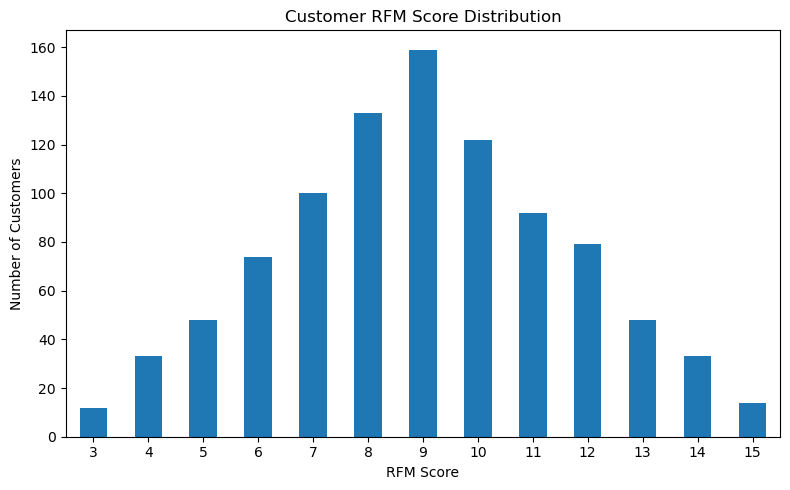

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

rfm["RFM_Score"].value_counts().sort_index().plot(
    kind="bar"
)

plt.title("Customer RFM Score Distribution")
plt.xlabel("RFM Score")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [13]:
import numpy as np

# Define customer segments
conditions = [
    (rfm["R_Score"] >= 4) & (rfm["M_Score"] >= 4),

    (rfm["R_Score"] >= 4) & (rfm["M_Score"] <= 3),

    (rfm["R_Score"] <= 2) & (rfm["M_Score"] >= 4),

    (rfm["R_Score"] <= 2) & (rfm["M_Score"] <= 3)
]

segment_names = [
    "High Value Recent",
    "Recent Low Value",
    "At Risk High Value",
    "Inactive Low Value"
]

rfm["Customer_Segment"] = np.select(
    conditions,
    segment_names,
    default="Regular Customers"
)

# Display customer segments
display(rfm.head(15))

# Segment counts
print("\nCustomer Segment Summary:")
print(rfm["Customer_Segment"].value_counts())

,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,Customer_Segment
Customer_ID,,,,,,,,
CUST1004,312,1,8321.54,1,1,1,3,Inactive Low Value
CUST1017,261,1,264230.68,2,1,5,8,At Risk High Value
CUST1026,95,1,164965.29,4,1,4,9,High Value Recent
CUST1032,249,1,146990.90,2,1,4,7,At Risk High Value
CUST1038,241,1,37068.40,2,1,1,4,Inactive Low Value
CUST1049,299,1,16714.64,1,1,1,3,Inactive Low Value
CUST1088,128,1,203819.75,4,1,4,9,High Value Recent
CUST1090,2,1,5263.79,5,1,1,7,Recent Low Value
CUST1094,196,1,211945.90,3,1,4,8,Regular Customers



Customer Segment Summary:
Customer_Segment
Inactive Low Value    232
Recent Low Value      214
Regular Customers     189
High Value Recent     165
At Risk High Value    147
Name: count, dtype: int64


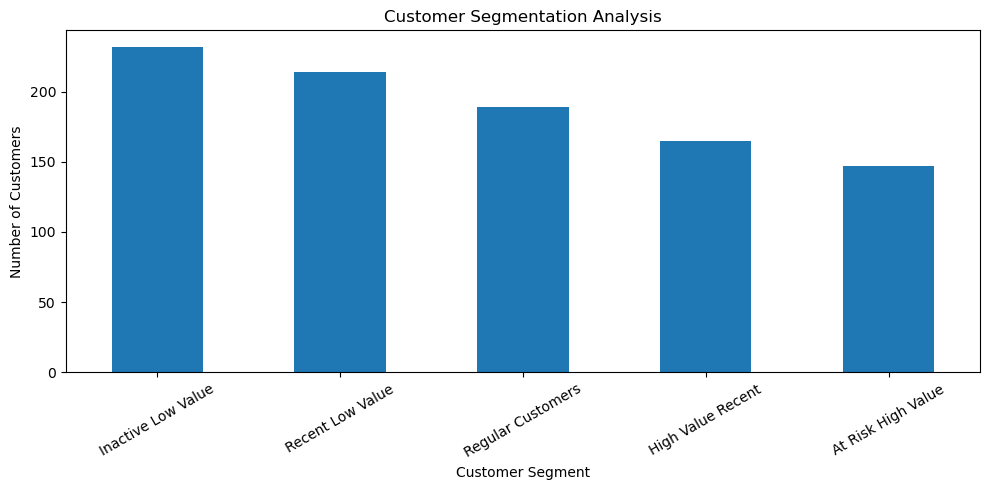

In [14]:
plt.figure(figsize=(10, 5))

rfm["Customer_Segment"].value_counts().plot(
    kind="bar"
)

plt.title("Customer Segmentation Analysis")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [15]:
# Segment-wise analysis
segment_summary = rfm.groupby("Customer_Segment").agg(
    Total_Customers=("Customer_Segment", "count"),
    Average_Recency=("Recency", "mean"),
    Average_Frequency=("Frequency", "mean"),
    Average_Monetary=("Monetary", "mean"),
    Total_Revenue=("Monetary", "sum")
).round(2)

# Add percentage contribution
segment_summary["Customer_Percentage"] = (
    segment_summary["Total_Customers"] /
    len(rfm) * 100
).round(2)

display(segment_summary)

,Total_Customers,Average_Recency,Average_Frequency,Average_Monetary,Total_Revenue,Customer_Percentage
Customer_Segment,,,,,,
At Risk High Value,147,291.35,1.03,262217.27,38545938.67,15.52
High Value Recent,165,66.79,1.19,267984.83,44217497.64,17.42
Inactive Low Value,232,288.41,1.00,63328.64,14692243.81,24.50
Recent Low Value,214,68.16,1.04,65684.07,14056391.72,22.60
Regular Customers,189,179.68,1.04,147552.21,27887367.81,19.96


In [16]:
import os

# Create Output folder
# os.makedirs( exist_ok=True)

# Export customer-level RFM data
rfm.to_csv(
    "Customer_RFM_Segmentation.csv",
    index=True
)

# Export segment summary
segment_summary.to_csv(
    "Segment_Summary.csv"
)

print("Files Exported Successfully!")
print("1. Customer_RFM_Segmentation.csv")
print("2. Segment_Summary.csv")

Files Exported Successfully!
1. Customer_RFM_Segmentation.csv
2. Segment_Summary.csv


In [17]:
print("Total Customers:", len(rfm))

print("\nFrequency Distribution:")
print(rfm["Frequency"].value_counts().sort_index())

print("\nMaximum Frequency:")
print(rfm["Frequency"].max())

Total Customers: 947

Frequency Distribution:
Frequency
1    895
2     51
3      1
Name: count, dtype: int64

Maximum Frequency:
3
